In [1]:
import numpy as np
import pandas as pd
import sklearn as sk

In [2]:
file_path = "Landing Zone Dataset - Sheet1.csv"
df = pd.read_csv(file_path)
df.head()

,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485,1
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913,1
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620,0
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006,1
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057,1


In [3]:
df.describe()

,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,8.257786,0.287347,0.335261,0.397403,0.245188,0.151231,0.219207,0.775345,0.550000
std,4.729597,0.157635,0.176202,0.229965,0.142418,0.050393,0.130930,0.100204,0.497577
min,0.000000,0.005368,0.000868,0.000004,0.005999,-0.018778,0.004051,0.600259,0.000000
25%,4.862294,0.167848,0.198709,0.196411,0.134075,0.117025,0.120339,0.689372,0.000000
50%,8.121824,0.266516,0.319744,0.398755,0.224382,0.151421,0.196254,0.776927,1.000000
75%,11.367954,0.390529,0.451383,0.589366,0.337315,0.186058,0.298400,0.863509,1.000000
max,27.631189,0.819733,0.901881,0.799831,0.756748,0.314608,0.765969,0.949867,1.000000


### Clean the dataframe by removing the negative brightness std values

In [4]:
df_clean = df[df["brightness_std"] >= 0]
df_clean.shape

(2995, 9)

#### Reset the index to align to new shape

In [5]:
df_clean = df_clean.reset_index(drop=True)

In [6]:
df_clean.describe()

,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label
count,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000,2995.000000
mean,8.256143,0.287278,0.335232,0.397729,0.245240,0.151502,0.219101,0.775494,0.550250
std,4.731952,0.157720,0.176280,0.229919,0.142503,0.049995,0.130922,0.100189,0.497552
min,0.000000,0.005368,0.000868,0.000004,0.005999,0.002267,0.004051,0.600259,0.000000
25%,4.859424,0.167708,0.198583,0.196533,0.134018,0.117132,0.120309,0.689548,0.000000
50%,8.119515,0.266243,0.319750,0.399016,0.224501,0.151476,0.195821,0.777167,1.000000
75%,11.370002,0.390730,0.451389,0.589569,0.337396,0.186150,0.298424,0.863746,1.000000
max,27.631189,0.819733,0.901881,0.799831,0.756748,0.314608,0.765969,0.949867,1.000000


#### No more negative values in any feature

In [7]:
y = df_clean["label"]
print(y.head())
print(y.shape)

0    1
1    1
2    0
3    1
4    1
Name: label, dtype: int64
(2995,)


In [8]:
X = df_clean.drop(columns="label")
print(X.shape)
X.head()

(2995, 8)


,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057


### Use train test split to get test data. It will be untouched until the final model testing for metrics

In [9]:
X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [10]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2396, 8)
(599, 8)
(2396,)
(599,)


In [11]:
print(y_train.mean())
print(y_test.mean())

0.5500834724540902
0.5509181969949917


#### It is an even class distribution

# 
### Check which model best fits our data
#### First is Logistic Resression, as it is the simplest model
#### Use K fold Cross Validation to get a robust measure of model performance
#### Use pipeline to simplify the code abit

In [12]:
LR_pipeline = sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                      ("log_reg", sk.linear_model.LogisticRegression(random_state=42))
                                    ]
                                  )

kfold_cv = sk.model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
LR_cv_results = sk.model_selection.cross_validate( LR_pipeline, 
                                                   X_train, y_train, 
                                                   scoring=metrics,
                                                   cv = kfold_cv, 
                                                   return_train_score=True
                                                 )


In [13]:
LR_cv_results

{'fit_time': array([0.01024604, 0.00959587, 0.00472188, 0.00530267, 0.00837994]),
 'score_time': array([0.0124321 , 0.0138514 , 0.016397  , 0.01925087, 0.01389456]),
 'test_accuracy': array([0.70416667, 0.67849687, 0.77453027, 0.7223382 , 0.7223382 ]),
 'train_accuracy': array([0.72442589, 0.73343766, 0.70944184, 0.72509129, 0.72509129]),
 'test_precision': array([0.70198675, 0.68333333, 0.77083333, 0.73897059, 0.73381295]),
 'train_precision': array([0.73029772, 0.7396293 , 0.71552472, 0.7283737 , 0.7287695 ]),
 'test_recall': array([0.8030303 , 0.77651515, 0.84090909, 0.76425856, 0.7756654 ]),
 'train_recall': array([0.79127135, 0.79506641, 0.78273245, 0.79810427, 0.7971564 ]),
 'test_f1': array([0.74911661, 0.72695035, 0.80434783, 0.75140187, 0.75415896]),
 'train_f1': array([0.75956284, 0.76634659, 0.74762121, 0.76164631, 0.76143051]),
 'test_roc_auc': array([0.78207421, 0.75262509, 0.83060254, 0.7840445 , 0.78557598]),
 'train_roc_auc': array([0.79478685, 0.79998615, 0.78178698, 0

#### We can see that metrics for train and test folds are similar
#### Model is fitting correctly
#### No overfitting or underfitting

In [14]:
LR_metrics = {
    "Accuracy" : LR_cv_results["test_accuracy"].mean(),
    "Precision" : LR_cv_results["test_precision"].mean(),
    "Recall" : LR_cv_results["test_recall"].mean(),
    "F1 Score" : LR_cv_results["test_f1"].mean(),
    "ROC AUC" : LR_cv_results["test_roc_auc"].mean()
}

LR_metrics    

{'Accuracy': np.float64(0.7203740431454418),
 'Precision': np.float64(0.7257873919018272),
 'Recall': np.float64(0.7920756999654338),
 'F1 Score': np.float64(0.7571951245018935),
 'ROC AUC': np.float64(0.7869844630886537)}

### Next Random Forest

In [15]:
RF_pipeline = sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                      ("rf", sk.ensemble.RandomForestClassifier(random_state=42))
                                    ]
                                  )

RF_cv_results = sk.model_selection.cross_validate(RF_pipeline, 
                                                  X_train, y_train, 
                                                   scoring=metrics,
                                                   cv = kfold_cv, 
                                                   return_train_score=True
                                                 )

RF_cv_results

{'fit_time': array([0.52850437, 0.74436331, 0.82990885, 0.96719646, 0.83721924]),
 'score_time': array([0.03317809, 0.03087497, 0.04970622, 0.0540204 , 0.05121136]),
 'test_accuracy': array([0.71458333, 0.68267223, 0.72442589, 0.68267223, 0.69102296]),
 'train_accuracy': array([1., 1., 1., 1., 1.]),
 'test_precision': array([0.71972318, 0.7       , 0.73571429, 0.70786517, 0.72030651]),
 'train_precision': array([1., 1., 1., 1., 1.]),
 'test_recall': array([0.78787879, 0.74242424, 0.78030303, 0.71863118, 0.7148289 ]),
 'train_recall': array([1., 1., 1., 1., 1.]),
 'test_f1': array([0.7522604 , 0.72058824, 0.75735294, 0.71320755, 0.71755725]),
 'train_f1': array([1., 1., 1., 1., 1.]),
 'test_roc_auc': array([0.75229728, 0.72303559, 0.79372798, 0.75929447, 0.74873257]),
 'train_roc_auc': array([1., 1., 1., 1., 1.])}

#### We see train metrics are 100% and test metrics are much lower
#### Overfitting. Need to apply pruning and early stopping

In [16]:
RF_pipeline2 = sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                       ("rf", sk.ensemble.RandomForestClassifier(n_estimators=50, 
                                                                                 max_depth=3, max_leaf_nodes=6, 
                                                                                 min_samples_split=500, min_samples_leaf=200, 
                                                                                 min_weight_fraction_leaf=0.4, 
                                                                                 min_impurity_decrease=0.33, 
                                                                                 ccp_alpha=0.2, 
                                                                                 random_state=42, n_jobs=-1))
                                     ]
                                   )

RF_cv_results2 = sk.model_selection.cross_validate(RF_pipeline, 
                                                  X_train, y_train, 
                                                   scoring=metrics,
                                                   cv = kfold_cv, 
                                                   return_train_score=True
                                                 )

RF_cv_results2

{'fit_time': array([0.78517103, 0.74140286, 0.60730791, 0.77855229, 0.82324672]),
 'score_time': array([0.05127525, 0.03119445, 0.04086041, 0.0516479 , 0.03794932]),
 'test_accuracy': array([0.71458333, 0.68267223, 0.72442589, 0.68267223, 0.69102296]),
 'train_accuracy': array([1., 1., 1., 1., 1.]),
 'test_precision': array([0.71972318, 0.7       , 0.73571429, 0.70786517, 0.72030651]),
 'train_precision': array([1., 1., 1., 1., 1.]),
 'test_recall': array([0.78787879, 0.74242424, 0.78030303, 0.71863118, 0.7148289 ]),
 'train_recall': array([1., 1., 1., 1., 1.]),
 'test_f1': array([0.7522604 , 0.72058824, 0.75735294, 0.71320755, 0.71755725]),
 'train_f1': array([1., 1., 1., 1., 1.]),
 'test_roc_auc': array([0.75229728, 0.72303559, 0.79372798, 0.75929447, 0.74873257]),
 'train_roc_auc': array([1., 1., 1., 1., 1.])}

#### Even with high regularisation values, the train metrics are 100% and test metrics don't improve
#### This model does not work for our data
#### Note: I have tried many values for each hyperparameter but there is no change in metrics

# 
### Next is SVM 

In [17]:
SVM_pipeline = sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                       ("svm", sk.svm.SVC(random_state=42))
                                     ]
                                   )

SVM_cv_results = sk.model_selection.cross_validate(SVM_pipeline, 
                                                  X_train, y_train, 
                                                   scoring=metrics,
                                                   cv = kfold_cv, 
                                                   return_train_score=True
                                                 )

SVM_cv_results

{'fit_time': array([0.16493368, 0.1219933 , 0.09531713, 0.09456086, 0.09287953]),
 'score_time': array([0.15544319, 0.16249442, 0.09623647, 0.0926249 , 0.09469914]),
 'test_accuracy': array([0.69166667, 0.68475992, 0.7348643 , 0.7223382 , 0.69311065]),
 'train_accuracy': array([0.76304802, 0.76630151, 0.76004173, 0.76160668, 0.76890975]),
 'test_precision': array([0.68471338, 0.69824561, 0.73702422, 0.73381295, 0.70714286]),
 'train_precision': array([0.75862069, 0.76957295, 0.7578125 , 0.75687285, 0.7642487 ]),
 'test_recall': array([0.81439394, 0.75378788, 0.80681818, 0.7756654 , 0.75285171]),
 'train_recall': array([0.83491461, 0.82068311, 0.82827324, 0.83507109, 0.83886256]),
 'test_f1': array([0.74394464, 0.72495446, 0.77034358, 0.75415896, 0.72928177]),
 'train_f1': array([0.79494128, 0.7943067 , 0.79147779, 0.79405137, 0.79981925]),
 'test_roc_auc': array([0.75910143, 0.73625793, 0.79837914, 0.77161667, 0.74660259]),
 'train_roc_auc': array([0.83637628, 0.84022902, 0.8287075 , 0

#### Model is able to fit our data
#### Collect average of these metrics

In [18]:
SVM_metrics = {
    "Accuracy" : SVM_cv_results["test_accuracy"].mean(),
    "Precision" : SVM_cv_results["test_precision"].mean(),
    "Recall" : SVM_cv_results["test_recall"].mean(),
    "F1 Score" : SVM_cv_results["test_f1"].mean(),
    "ROC AUC" : SVM_cv_results["test_roc_auc"].mean()
}

SVM_metrics    

{'Accuracy': np.float64(0.705347947112039),
 'Precision': np.float64(0.7121878036135396),
 'Recall': np.float64(0.780703422053232),
 'F1 Score': np.float64(0.7445366825286794),
 'ROC AUC': np.float64(0.7623915528453395)}

# 
### Next is KNN

In [19]:
KNN_pipeline = sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                       ("knn", sk.neighbors.KNeighborsClassifier(n_neighbors=5))
                                     ]
                                   )

KNN_cv_results = sk.model_selection.cross_validate(KNN_pipeline, 
                                                  X_train, y_train, 
                                                   scoring=metrics,
                                                   cv = kfold_cv, 
                                                   return_train_score=True
                                                 )

KNN_cv_results

{'fit_time': array([0.0064342 , 0.0049324 , 0.00432897, 0.00437808, 0.00450754]),
 'score_time': array([0.03644586, 0.02666688, 0.03018475, 0.02715588, 0.02811408]),
 'test_accuracy': array([0.62083333, 0.63256785, 0.68267223, 0.66805846, 0.6263048 ]),
 'train_accuracy': array([0.78079332, 0.78247261, 0.75117371, 0.77777778, 0.78247261]),
 'test_precision': array([0.63945578, 0.66541353, 0.69858156, 0.68571429, 0.64685315]),
 'train_precision': array([0.78661844, 0.78771454, 0.75644444, 0.78055308, 0.78180212]),
 'test_recall': array([0.71212121, 0.67045455, 0.74621212, 0.73003802, 0.70342205]),
 'train_recall': array([0.82542694, 0.82732448, 0.80740038, 0.82938389, 0.83886256]),
 'test_f1': array([0.67383513, 0.66792453, 0.72161172, 0.70718232, 0.67395264]),
 'train_f1': array([0.80555556, 0.80703378, 0.78109224, 0.80422794, 0.80932785]),
 'test_roc_auc': array([0.66446584, 0.66804968, 0.71695736, 0.70670504, 0.66941276]),
 'train_roc_auc': array([0.8638564 , 0.86272458, 0.84083808, 0

#### We can see noticable difference in train and test metrics
#### Try with different K values

In [20]:
KNN_pipeline2 = sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                       ("knn", sk.neighbors.KNeighborsClassifier(n_neighbors=35))
                                     ]
                                   )

KNN_cv_results2 = sk.model_selection.cross_validate(KNN_pipeline2, 
                                                  X_train, y_train, 
                                                   scoring=metrics,
                                                   cv = kfold_cv, 
                                                   return_train_score=True
                                                 )

KNN_cv_results2

{'fit_time': array([0.00840783, 0.00746036, 0.00477576, 0.00432587, 0.00454021]),
 'score_time': array([0.07299566, 0.06228685, 0.04125381, 0.03995252, 0.04248095]),
 'test_accuracy': array([0.66666667, 0.6743215 , 0.71607516, 0.6993737 , 0.70772443]),
 'train_accuracy': array([0.72703549, 0.72926448, 0.72143975, 0.7219614 , 0.71935316]),
 'test_precision': array([0.66455696, 0.67880795, 0.71192053, 0.70446735, 0.70568562]),
 'train_precision': array([0.72292191, 0.72961373, 0.71594684, 0.7160596 , 0.71205906]),
 'test_recall': array([0.79545455, 0.77651515, 0.81439394, 0.77946768, 0.80228137]),
 'train_recall': array([0.81688805, 0.80645161, 0.81783681, 0.81990521, 0.82274882]),
 'test_f1': array([0.72413793, 0.72438163, 0.75971731, 0.7400722 , 0.75088968]),
 'train_f1': array([0.76703786, 0.76611086, 0.76350753, 0.76447194, 0.76341249]),
 'test_roc_auc': array([0.75456825, 0.72752819, 0.7889623 , 0.77246163, 0.74927827]),
 'train_roc_auc': array([0.79501248, 0.7982997 , 0.79327717, 0

#### I've simply increased the K value until I was satisfied with the difference between train and test metrics
#### We can calculate the best K value using elbow method later
#### Collect the metrics

In [21]:
KNN_metrics2 = {
    "Accuracy" : KNN_cv_results2["test_accuracy"].mean(),
    "Precision" : KNN_cv_results2["test_precision"].mean(),
    "Recall" : KNN_cv_results2["test_recall"].mean(),
    "F1 Score" : KNN_cv_results2["test_f1"].mean(),
    "ROC AUC" : KNN_cv_results2["test_roc_auc"].mean()
}

KNN_metrics2   

{'Accuracy': np.float64(0.6928322894919972),
 'Precision': np.float64(0.6930876823054991),
 'Recall': np.float64(0.7936225371586588),
 'F1 Score': np.float64(0.7398397505690358),
 'ROC AUC': np.float64(0.7585597268022678)}

In [22]:
all_metrics = {"LogReg" : LR_metrics,
               "SVM" : SVM_metrics, 
               "KNN" : KNN_metrics2
              }
metric_df = pd.DataFrame(all_metrics)
metric_df.T

,Accuracy,Precision,Recall,F1 Score,ROC AUC
LogReg,0.720374,0.725787,0.792076,0.757195,0.786984
SVM,0.705348,0.712188,0.780703,0.744537,0.762392
KNN,0.692832,0.693088,0.793623,0.739840,0.758560


#### As we see here, they have similar metrics 
#### We need to use hyperparameter tuning to get the best possible model out of these and then test them on test data

In [23]:
LR_grid_pipeline = sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                           ("logR", sk.linear_model.LogisticRegression(solver="saga", random_state=42))
                                         ]
                                       )

LR_params = {
    "logR__C" : [0.001, 0.01, 0.1, 1, 10, 100],
    "logR__penalty" : ["l1", "l2"],
    "logR__max_iter" : [100, 300, 500, 1000]
}
    

kfold_cv = sk.model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=42) 

LR_grid_search = sk.model_selection.GridSearchCV(LR_grid_pipeline, LR_params,
                                                 cv = kfold_cv, 
                                                 scoring="f1",
                                                 n_jobs=-1, verbose=1, 
                                                 return_train_score=True
                                                )
LR_grid_search.fit(X_train, y_train)


Fitting 5 folds for each of 48 candidates, totalling 240 fits


,estimator,Pipeline(step...ver='saga'))])
,param_grid,"{'logR__C': [0.001, 0.01, ...], 'logR__max_iter': [100, 300, ...], 'logR__penalty': ['l1', 'l2']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,copy,True


In [24]:
LR_grid_search.best_params_

{'logR__C': 0.001, 'logR__max_iter': 100, 'logR__penalty': 'l2'}

In [25]:
LR_grid_df = pd.DataFrame(LR_grid_search.cv_results_)
LR_grid_df[["param_logR__C", "param_logR__max_iter", "param_logR__penalty", "mean_test_score", "mean_train_score"]].sort_values(by="mean_test_score", ascending=False).head(10)

,param_logR__C,param_logR__max_iter,param_logR__penalty,mean_test_score,mean_train_score
3,0.001,300,l2,0.762735,0.763773
5,0.001,500,l2,0.762735,0.763773
7,0.001,1000,l2,0.762735,0.763773
1,0.001,100,l2,0.762735,0.763773
13,0.010,500,l2,0.759437,0.762112
15,0.010,1000,l2,0.759437,0.762112
9,0.010,100,l2,0.759437,0.762112
11,0.010,300,l2,0.759437,0.762112
16,0.100,100,l1,0.759432,0.759573
18,0.100,300,l1,0.759432,0.759573


#### We see C = 0.001 performs marginally better than C = 0.01 
#### We also see that the difference between train and test scores is so small, it means it is generalising perfectly 
#### Note: Using Precision as the score to maximise caused multiple C values and penalty types to have the same score 

In [26]:
SVM_grid_pipeline =  sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                           ("svm", sk.svm.SVC(random_state=42))
                                           ]
                                         )

SVM_params = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "svm__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1]
}

SVM_grid_search = sk.model_selection.GridSearchCV(SVM_grid_pipeline, SVM_params, 
                                                  cv = kfold_cv, 
                                                  scoring="f1", 
                                                  n_jobs=-1, verbose=1, 
                                                  return_train_score=True
                                                 )

SVM_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'svm__C': [0.001, 0.01, ...], 'svm__gamma': ['scale', 'auto', ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,copy,True


In [27]:
SVM_grid_search.best_params_

{'svm__C': 0.1, 'svm__gamma': 0.01}

In [28]:
SVM_grid_df = pd.DataFrame(SVM_grid_search.cv_results_)
SVM_grid_df[["param_svm__C", "param_svm__gamma", "mean_test_score", "mean_train_score"]].sort_values(by="mean_test_score", ascending=False).head(10)

,param_svm__C,param_svm__gamma,mean_test_score,mean_train_score
15,0.1,0.01,0.765363,0.764266
20,1.0,0.001,0.760354,0.763098
21,1.0,0.01,0.757015,0.762924
32,100.0,0.001,0.756656,0.761542
26,10.0,0.001,0.755298,0.760543
27,10.0,0.01,0.754732,0.766051
16,0.1,0.1,0.754193,0.766223
12,0.1,scale,0.752444,0.768825
13,0.1,auto,0.752444,0.768825
33,100.0,0.01,0.750370,0.773861


#### Here C = 0.1, gamma = 0.01 came out as the best hyperparameters
#### Low difference between train and test score implies good fit

In [29]:
KNN_grid_pipeline = sk.pipeline.Pipeline( [ ("scaler", sk.preprocessing.StandardScaler()), 
                                       ("knn", sk.neighbors.KNeighborsClassifier())
                                     ]
                                   )

KNN_params = {
    "knn__n_neighbors": np.arange(1, 121, 2),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

KNN_grid_search = sk.model_selection.GridSearchCV(KNN_grid_pipeline, KNN_params, 
                                                  cv = kfold_cv, 
                                                  scoring="f1", 
                                                  n_jobs=-1, verbose=1, 
                                                  return_train_score=True
                                                 )

KNN_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits


,estimator,Pipeline(step...lassifier())])
,param_grid,"{'knn__metric': ['euclidean', 'manhattan'], 'knn__n_neighbors': array([ 1, ...15, 117, 119]), 'knn__weights': ['uniform', 'distance']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,copy,True


In [30]:
KNN_grid_search.best_params_

{'knn__metric': 'manhattan',
 'knn__n_neighbors': np.int64(111),
 'knn__weights': 'uniform'}

In [31]:
KNN_grid_search.best_score_

np.float64(0.7613810041556629)

In [32]:
KNN_grid_df = pd.DataFrame(KNN_grid_search.cv_results_)
KNN_grid_df[["param_knn__metric", "param_knn__n_neighbors", "param_knn__weights", "mean_test_score", "mean_train_score"]].sort_values(by="mean_test_score", ascending=False).head(30)

,param_knn__metric,param_knn__n_neighbors,param_knn__weights,mean_test_score,mean_train_score
230,manhattan,111,uniform,0.761381,0.764194
224,manhattan,105,uniform,0.761289,0.764855
118,euclidean,119,uniform,0.761216,0.763759
231,manhattan,111,distance,0.760832,1.000000
225,manhattan,105,distance,0.760685,1.000000
211,manhattan,91,distance,0.760224,1.000000
212,manhattan,93,uniform,0.760198,0.762931
113,euclidean,113,distance,0.759978,1.000000
226,manhattan,107,uniform,0.759944,0.763520
227,manhattan,107,distance,0.759911,1.000000


#### Elbow graph to get the best K value

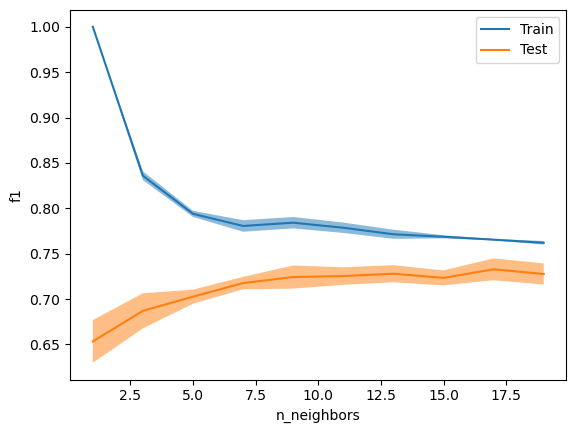

In [33]:
sk.model_selection.ValidationCurveDisplay.from_estimator(
    sk.neighbors.KNeighborsClassifier(),
    X_train, y_train, 
    param_name="n_neighbors",
    param_range=np.arange(1, 21, 2),
    cv=5,
    scoring="f1",
    score_name="f1",
    score_type="both"
)

In [34]:
KNN_params = {
    "knn__n_neighbors": np.arange(1, 11, 2),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

KNN_grid_search2 = sk.model_selection.GridSearchCV(KNN_grid_pipeline, KNN_params, 
                                                  cv = kfold_cv, 
                                                  scoring="f1", 
                                                  n_jobs=-1, verbose=1, 
                                                  return_train_score=True
                                                 )

KNN_grid_search2.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,Pipeline(step...lassifier())])
,param_grid,"{'knn__metric': ['euclidean', 'manhattan'], 'knn__n_neighbors': array([1, 3, 5, 7, 9]), 'knn__weights': ['uniform', 'distance']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,copy,True


In [35]:
KNN_grid_search2.best_params_

{'knn__metric': 'euclidean',
 'knn__n_neighbors': np.int64(9),
 'knn__weights': 'uniform'}

In [36]:
KNN_grid_search2.best_score_

np.float64(0.7134282009308598)

In [37]:
KNN_grid_df2 = pd.DataFrame(KNN_grid_search2.cv_results_)

In [38]:
KNN_grid_df2[["param_knn__metric", "param_knn__n_neighbors", "param_knn__weights", "mean_test_score", "mean_train_score"]].sort_values(by="mean_test_score", ascending=False).head(30)

,param_knn__metric,param_knn__n_neighbors,param_knn__weights,mean_test_score,mean_train_score
8,euclidean,9,uniform,0.713428,0.783070
9,euclidean,9,distance,0.713279,1.000000
18,manhattan,9,uniform,0.712236,0.781383
19,manhattan,9,distance,0.711563,1.000000
16,manhattan,7,uniform,0.703637,0.790704
17,manhattan,7,distance,0.701193,1.000000
6,euclidean,7,uniform,0.699058,0.788423
7,euclidean,7,distance,0.698103,1.000000
14,manhattan,5,uniform,0.693727,0.804284
15,manhattan,5,distance,0.691947,1.000000


#### From elbow graph, we can see that at K = 7, the gain in metric diminishes
#### But from grid search, we saw that K = 111 gets the highest score
#### Also using Manhattan distance and uniform weights works the best

# 
#### All three models gave similar F1 scores on their best hyperparameters (76%)
#### We can choose the easiest to implement and interpret model, which is Logistic Regression
##
### Implementing Logistic Regression with C = 0.001, penalty = l2

In [39]:
scaler = sk.preprocessing.StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

final_model = sk.linear_model.LogisticRegression(penalty="l2", C=0.001, max_iter=100)
final_model.fit(X_train_scaled, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.001
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [40]:
X_test_scaled = scaler.transform(X_test)

y_pred = final_model.predict(X_test_scaled)

In [61]:
model_metrics = sk.metrics.classification_report(y_test, y_pred, output_dict=True)

In [65]:
model_metrics_df = pd.DataFrame(model_metrics)
model_metrics_df.to_csv("Logistic Regression Test Metrics.csv")

In [42]:
y_pred_proba = final_model.predict_proba(X_test_scaled)[:, 1]

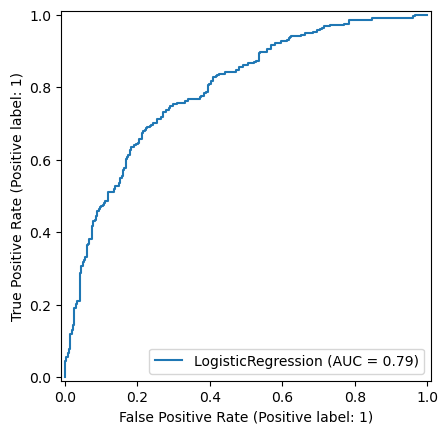

In [66]:
sk.metrics.RocCurveDisplay.from_estimator(final_model, X_test_scaled, y_test)
plt.savefig("Logistic Regression ROC.png")

In [44]:
sk.metrics.roc_auc_score(y_test, y_pred_proba)

0.7942548158161541

### We also train SVM using C = 0.1 and gamma = 0.01

In [45]:
#scaler2 = sk.preprocessing.StandardScaler()
#X_train_scaled2 = scaler.fit_transform(X_train)

final_model2 = sk.svm.SVC(C=0.1, gamma=0.01)
final_model2.fit(X_train_scaled, y_train)

y_pred2 = final_model2.predict(X_test_scaled)
sk.metrics.classification_report(y_test, y_pred2, output_dict=True)

{'0': {'precision': 0.7294685990338164,
  'recall': 0.5613382899628253,
  'f1-score': 0.634453781512605,
  'support': 269.0},
 '1': {'precision': 0.6989795918367347,
  'recall': 0.8303030303030303,
  'f1-score': 0.7590027700831025,
  'support': 330.0},
 'accuracy': 0.7095158597662772,
 'macro avg': {'precision': 0.7142240954352757,
  'recall': 0.6958206601329278,
  'f1-score': 0.6967282757978537,
  'support': 599.0},
 'weighted avg': {'precision': 0.7126716501606329,
  'recall': 0.7095158597662772,
  'f1-score': 0.7030700857334132,
  'support': 599.0}}

In [46]:
y_pred_proba2 = final_model2.decision_function(X_test_scaled)

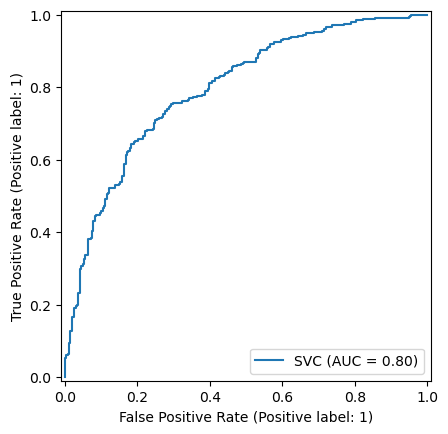

In [47]:
sk.metrics.RocCurveDisplay.from_estimator(final_model2, X_test_scaled, y_test)

In [48]:
sk.metrics.roc_auc_score(y_test, y_pred_proba2)

0.7951898163794074

### Divide the test dataset into grid
### Generate heatmap representing safe landing spaces on grid

In [49]:
X_test_scaled.shape

(599, 8)

In [50]:
new_row = np.array([[0, 0, 0, 0, 0, 0, 0, 0]])
new_row.shape

(1, 8)

In [51]:
new_X_test = np.append(X_test_scaled, new_row, axis=0)
new_X_test

array([[-0.53864035, -1.09575804, -1.15082164, ..., -1.5961415 ,
        -0.10607107, -1.7175232 ],
       [ 0.50588329, -0.81151188,  0.18475866, ..., -0.47297934,
         2.69710617, -1.53055397],
       [-0.71497655, -0.06170621, -0.22245703, ...,  0.21448817,
         0.56745797, -0.20811432],
       ...,
       [ 0.60175099, -1.38909776,  1.67023388, ...,  0.64095423,
         0.40613387,  0.1958833 ],
       [-0.12088709, -0.65016376, -0.68494149, ...,  0.2643393 ,
        -1.36134533,  1.12511407],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ]], shape=(600, 8))

In [52]:
new_y_test = np.append(y_test, np.array([0]), axis=0)
print(new_y_test.shape)
new_y_test

(600,)


array([0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0,

In [53]:
new_y_pred = final_model.predict(new_X_test)
new_y_pred.shape

(600,)

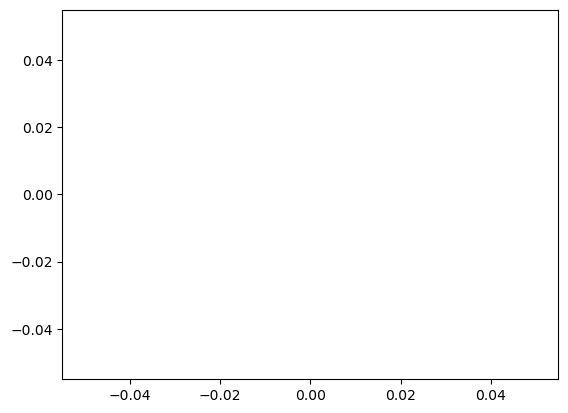

In [54]:
import matplotlib.pyplot as plt
plot = plt.plot()

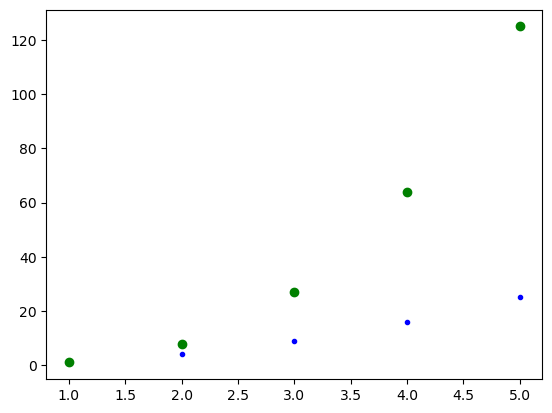

In [55]:
x = np.array([1,2,3,4,5])
y = np.array([1,4,9,16,25])
z = np.array([1,8,27,64,125])
plot = plt.plot(x, y, "b.")
plot = plt.plot(x, z, "go")

### Heatmaps

In [ ]:
y_test_grid = new_y_test.reshape(20, 30)
for x in range(y_test_grid.shape[0]):
    for y in range(y_test_grid.shape[1]):
        if y_test_grid[x][y] == 0:
            res = "rs"
        else:
            res = "gs"

        plt.plot(x, y, res)

plt.title(label="True Heatmap")
plt.savefig("True Heatmap.png")

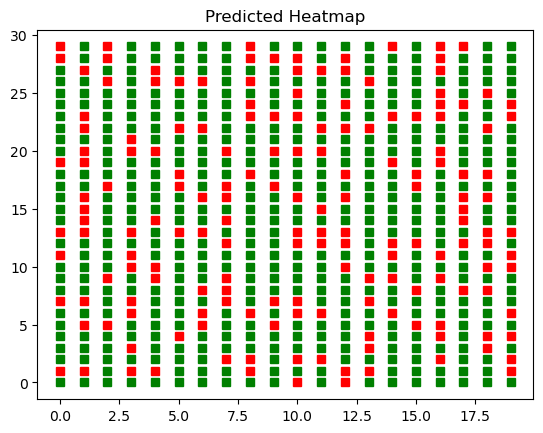

In [57]:
y_pred_grid = new_y_pred.reshape(20, 30)
for x in range(y_pred_grid.shape[0]):
    for y in range(y_pred_grid.shape[1]):
        if y_pred_grid[x][y] == 0:
            res = "rs"
        else:
            res = "gs"

        plt.plot(x, y, res)

plt.title(label="Predicted Heatmap")
plt.savefig("Pred Heatmap.png")

In [58]:
grid_table = (y_test_grid == y_pred_grid)
grid_table.mean()

np.float64(0.6916666666666667)

In [59]:
table = (new_y_test == new_y_pred) 

table.mean()

np.float64(0.6916666666666667)

### Export the model details so they can be used by others

In [67]:
import joblib
joblib.dump(final_model, "drone_landing_log_reg_predictor.pkl")

['drone_landing_log_reg_predictor.pkl']

In [68]:
joblib.dump(scaler, "drone_landing_log_reg_scaler.pkl")

['drone_landing_log_reg_scaler.pkl']

### Peak inside model

In [71]:
print(scaler.feature_names_in_)
print(scaler.mean_)
print(scaler.var_)
print(final_model.coef_)

['slope_deg' 'roughness' 'edge_density' 'ndvi_mean' 'shadow_fraction'
 'brightness_std' 'object_density' 'confidence_score']
[8.27535502 0.2896639  0.3330764  0.39709295 0.24476269 0.15197394
 0.21871971 0.77552264]
[2.24657940e+01 2.53915328e-02 3.07335516e-02 5.36229896e-02
 1.98538859e-02 2.46013408e-03 1.66758174e-02 1.00748800e-02]
[[-0.23412279 -0.18070188 -0.15587399  0.12438389 -0.08730163  0.00631112
  -0.07545972 -0.00204202]]


#### As we can see, for a safe landing the model prefers lower values of slope, roughness, edge density, shadow fraction and object density 
#### This is the same as the intuitive thinking
#### But the model prefers higher ndvi values, meaning more foliage or plants
#### This was unexpected
#### The brightness and confidence score have very low impact compared to other features
#### But we also have to consider that their range of values in the data. The mean of confidence score was 0.77 which is pretty high. So, the values in the dataset were already of high confidence
#### If we were to use the model to predict with a confidence score which is out of range of our training data, the model will make mistakes
#### It is important to check that the values used to predict are in the same range as the data used to train the model